In [3]:
import BPTK_Py
from BPTK_Py import Model
from BPTK_Py import sd_functions as sd

print(BPTK_Py.__version__)

bptk = BPTK_Py.bptk()

from BPTK_Py import Model
from BPTK_Py import sd_functions as sd
import BPTK_Py.sddsl.functions as sddsl

bptk = BPTK_Py.bptk()

print("BPTK-Py erfolgreich geladen!")

from BPTK_Py import Model
from BPTK_Py import sd_functions as sd
import BPTK_Py
print(BPTK_Py.__version__)
import importlib.metadata

import random  # Importiert das gesamte Modul für random.seed()
from random import randint as rn  # Importiert gezielt randint unter dem Alias r

import BPTK_Py.sddsl.functions as sd


bptk = BPTK_Py.bptk()


#https://www.waldwissen.net/de/technik-und-planung/landschaftsentwicklung/waldausdehnung-im-schweizer-alpenraum
# Im Vormarsch ist der Wald also auf den so genannten Grenzertragslagen.
#Brachlandes
#Kommt der Wald trotzdem unverdrossen zurück? Wirken die finanziellen Anreize zur Aufrechterhaltung der Bewirtschaftung nicht?
#https://www.wsl.ch/de/news/waldbericht-2025-schweizer-wald-unter-anpassungsdruck/

#erster zirkel Landwirtschat->Freie Fläche->Waldwachstum
#zweiter zirkel totholz bildung waldgesundheit and totholz reabsorption
#dirtter zirkel natural desaster anfälligkeit wegen sinkender waldgesundheit?


0.38.4
BPTK-Py erfolgreich geladen!
0.38.4


In [ ]:
%pip install --force-reinstall --no-deps --no-cache-dir Werkzeug==2.2.3



Jahr	Intensivierungsindex \(I\)
1980	0,90
1990	1,10
2000	1,35
2010	1,60
2020	1,85
2026	2,00

Begründung:
- Die Zahl der Landwirtschaftsbetriebe sank von rund 93'000 (1990) auf 47'000 (2024) (−49 %), während sich die durchschnittliche Betriebsgrösse von 11,5 ha auf 22,1 ha nahezu verdoppelte. Das ist ein klarer Indikator für Intensivierung und Strukturwandel.
  OECD+1
- Auch in Voralpen- und Alpenregionen zeigen Agroscope-Studien zwischen 2000 und 2020 eine stärkere Spezialisierung und innere Aufstockung der Betriebe.
  agroscope.admin.ch
Falls du jährliche Werte brauchst, kannst du zwischen den Stützpunkten linear interpolieren.
2. Einfluss auf die Aufgabe von Agrarflächen in den Alpen
Hier ist der Zusammenhang wichtig: Die Intensivierung führt nicht direkt zur Wiederbewaldung, sondern zur räumlichen Konzentration der Landwirtschaft.

Der Mechanismus lautet:
1. produktive Tal- und Hanglagen werden stärker mechanisiert und intensiviert,
2. steile, schwer erreichbare Flächen werden wirtschaftlich unattraktiv,
3. diese Flächen werden aufgegeben,
4. zunächst entstehen Gebüsch und Strauchvegetation,
5. später setzt natürliche Wiederbewaldung ein.
   bafu.admin.ch+1
Geschätzter Zusammenhang für dein Modell
Ich würde die jährliche Aufgabequote der alpinen Nutzfläche an den Intensivierungsindex koppeln.


Umwandlung in Wald und Gehölze

Rund 30 % der Landwirtschaftsflächen, die zwischen 1985 und 2018 ihre Nutzung verloren, wurden zu Wald oder Gehölzen. Besonders betroffen waren Alpweiden.
swissstats.bfs.admin.ch

In [2]:

#growth = model.flow("growth")

In [26]:
#Klimate severity to acid_deposition und drought_heat

#Waldflächenverlust: Eine Waldfläche wird dauerhaft einer anderen Nutzung zugeführt. Das gehört in die Waldflächenbilanz. Waldschäden und Mortalität:
bptk = BPTK_Py.bptk()

model = Model(    starttime=1980,
    stoptime=2026,
    dt=1.0,
    name="SwissForest")

##Parameters
rs=0.01
r0=0.002
alpha=0.3
biomass_factor = 1.0


# Klimaschäden
k_climate = 0.025
k_drought = 0.035
k_acid = 0.010

# Ereignisschäden
k_events = 0.020

# Mortalität
base_mortality = 0.005
mortality_climate = 0.025

# Kronendichte
canopy_recovery = 0.025
canopy_damage = 0.035

# Totholz
deadwood_decomposition_rate = 0.05
deadwood_removal_rate = 0.01


#stock Ein Stock repräsentiert den aktuellen Zustand des Systems Ein Stock repräsentiert den aktuellen Zustand des Syste


forest_area = model.stock("forest_area")
forest_health = model.stock("forest_health")
wald_verlust = model.stock("wald_verlust")
deadwood=model.stock("deadwood")
canopy_density = model.stock("canopy_density")

canopy_density.initial_value = 1.0
deadwood.initial_value = 0.0
#agrar
#intensity_agrar = model.stock("intensity_agrar")
Agrarfläche=model.stock("agrar")
#space
freespace=model.stock("freespace")
#climate
#swiss_climate = model.stock("swiss_climate")

#initial vars
#forrest
forest_area.initial_value=1.15#millionen hektar
forest_health.initial_value=1.0
wald_verlust.initial_value = 0.0
#agrar
#intensity_agrar.initial_value=0.9
freespace.initial_value = 0.122
Agrarfläche.initial_value=4.129100*0.35#originally round 35% of swissagrar area is in the mountenous area in which most of the growth happened

#Region (Alpensüdseite mit einem Waldanteil von knapp 55 %. Jura mit 40 %,  Voralpen mit 35 % und die Alpen mit 28 %.  Mittelland 24%)
#externe Zeitreihen
climate_data = model.converter("climate_data")
agrar_data = model.converter("agrar_data")



#flow
natural_growth = model.flow("_ngrowth")#freespace → forest_area
wiederaufforstung=model.flow("_wiederaufforstung")#freespace → forest_area
Rodung=model.flow("_rodung")#forest_area → freespace
verlust_durch_n_ereignissse=model.flow("_verlust")
decrease_agrar=model.flow("_decrease_agrar")#Agrarfläche → freespace
damage_from_climate=model.flow("_damage_from_climate")
damage_from_events=model.flow("_damage_from_events")
deadwood_decomposition = model.flow("deadwood_decomposition")
deadwood_removal = model.flow("deadwood_removal")
deadwood_reabsorption=model.flow("_deadwood_reabsorption")
#climate_severity=model.flow("_climate_severity")

#flow equation /Converter
climate_severity = model.converter("climate_severity")
drought_heat = model.converter("drought_heat")
acid_deposition = model.converter("acid_deposition")
event_intensity = model.converter("event_intensity")

forest_resilience = model.converter("forest_resilience")
vulnerability = model.converter("vulnerability")

vulnerability.equation = 1.0 - forest_resilience

forest_resilience.equation = forest_health
drought_heat.equation = sd.lookup(sd.time(), "drought_heat")

acid_deposition.equation = sd.lookup( sd.time(), "acid_deposition")

event_intensity.equation = sd.lookup(sd.time(), "event_intensity")

# Kombinierter Belastungsindex
climate_severity.equation = (0.7 * drought_heat+ 0.3 * acid_deposition)

# Zusätzliche Flows
health_recovery = model.flow("health_recovery")
health_damage = model.flow("health_damage")

climate_data.equation = sd.lookup(sd.time(), "climate_data")
agrar_data.equation = sd.lookup(sd.time(), "agrar_data")

# Vorläufiger Klimabelastungsindex


decrease_agrar.equation = Agrarfläche * (
    r0 * (1 + alpha * (agrar_data - 1)))

natural_growth.equation=freespace*rs*forest_health
wiederaufforstung.equation = 0.0

Rodung.equation = 0.0





#delta wald
delta_wald=natural_growth+wiederaufforstung-Rodung-verlust_durch_n_ereignissse




random.seed(123)

#climate_severity.equation = climate_data * sd.random(0, 1)
#damage_from_climate.equation=climate_severity

damage_from_climate.equation = (forest_area * k_climate * drought_heat)


#if climate_severity>0.5:

 #   damage_from_events.equation= (climate_severity*rn(0, 1))/forest_health
#else:
 #   damage_from_events.equation=0

#damage_from_events.equation = sd.If(climate_severity > 0.5,
  #  forest_area * 0.002 * climate_severity,0.0)

damage_from_events.equation = (forest_area * k_events * event_intensity)

verlust_durch_n_ereignissse.equation = (damage_from_events)

health_recovery.equation = ( (1.0 - forest_health) * 0.05)

#health_damage.equation = ( forest_health * climate_severity * 0.02)

#health_damage.equation = (forest_health* (k_drought * drought_heat + k_acid * acid_deposition
 #       + k_events * event_intensity    ))

health_damage.equation = (forest_health * 0.01)



deadwood_decomposition.equation = (    deadwood * 0.05)
deadwood_removal.equation = (    Rodung * 0.05)
deadwood_reabsorption.equation = ( deadwood_decomposition)

# Waldfläche

forest_area.equation = (
    natural_growth
    + wiederaufforstung
    - Rodung
    #- verlust_durch_n_ereignissse#
)

# Landwirtschaft

Agrarfläche.equation = -decrease_agrar

# Freie Fläche

freespace.equation = (decrease_agrar
    + Rodung
    - natural_growth
    - wiederaufforstung)

# Waldgesundheit
#forest_health.inflows = [    health_recovery]

#forest_health.outflows = [    health_damage]

forest_health.equation = health_recovery - health_damage

# Totholz
#deadwood.inflows = [
    # Hier später den Totholzeintrag ergänzen]

#deadwood.outflows = [    deadwood_decomposition]
tree_mortality = model.flow("tree_mortality")

tree_mortality.equation = (
    forest_area
    * ( base_mortality
        + mortality_climate * climate_severity
        * (1.0 - forest_health)    ))



deadwood_formation = model.flow("deadwood_formation")

deadwood_formation.equation =  (damage_from_events + tree_mortality * biomass_factor)

print("Deadwood formation:")
print(deadwood_formation.equation)
#deadwood.equation = (    deadwood_formation - deadwood_decomposition)

deadwood.equation = (
    deadwood_formation
    - deadwood_decomposition
    - deadwood_removal
)
canopy_regrowth = model.flow("canopy_regrowth")
canopy_loss = model.flow("canopy_loss")

canopy_regrowth.equation = (
    (1.0 - canopy_density)
    * canopy_recovery
)

canopy_loss.equation = (
    canopy_density
    * (
        canopy_damage * climate_severity
        + mortality_climate * (tree_mortality / forest_area)
    )
)

canopy_density.equation = (canopy_regrowth - canopy_loss)



# Prüfen, ob die Verknüpfungen tatsächlich am Stock angekommen sind
#print("Forest inflows:", forest_area.inflows)
#print("Forest outflows:", forest_area.outflows)

#print("Health inflows:", forest_health.inflows)
#print("Health outflows:", forest_health.outflows)

#print("Growth equation:", natural_growth.equation)
#print("Health damage equation:", health_damage.equation)

# Lookup-Daten direkt dem Modell geben
model.points["climate_data"] = [
    [1980, 1.7], [1981, 1.72], [1982, 1.68],
    [1983, 1.75], [1985, 1.5], [1990, 1.1],
    [1995, 1.2], [2000, 0.9], [2003, 0.1],
    [2005, 0.8], [2010, 1.1], [2015, 0.6],
    [2020, 0.4], [2025, 0.2], [2026, 2.1]
]

model.points["agrar_data"] = [
    [1980, 0.90], [1990, 1.10], [2000, 1.35],
    [2010, 1.60], [2020, 1.85], [2026, 2.00]
]

model.points["drought_heat"] = [
    [1980, 0.10],
    [1990, 0.15],
    [2000, 0.25],
    [2003, 0.75],
    [2010, 0.30],
    [2015, 0.60],
    [2020, 0.75],
    [2025, 0.85],
    [2026, 0.90]
]

model.points["acid_deposition"] = [
    [1980, 0.90],
    [1990, 0.85],
    [2000, 0.65],
    [2010, 0.45],
    [2015, 0.40],
    [2020, 0.35],
    [2025, 0.30],
    [2026, 0.30]
]

model.points["event_intensity"] = [
    [1980, 0.10],
    [1990, 0.15],
    [2000, 0.20],
    [2003, 0.40],
    [2010, 0.20],
    [2015, 0.35],
    [2020, 0.45],
    [2025, 0.50],
    [2026, 0.55]
]

# Direkte Simulation ohne Scenario Manager


#print(df_direct)

# Nichtnegative Bestände
forest_area.non_negative = True
Agrarfläche.non_negative = True
freespace.non_negative = True
deadwood.non_negative = True


print("Growth rate:", rs)
print("Growth equation:", natural_growth.equation)
print("Forest equation:", forest_area.equation)
print("Agriculture equation:", Agrarfläche.equation)



#Strukturwandel im Berggebiet: Die Zahl der Bergbetriebe nimmt massiv ab, während die verbleibenden Höfe wachsen. Am Beispiel Graubünden sank die Zahl der Betriebe innerhalb von 30 Jahren (1990–2020) um über 51 %.
#Gesamtflächenverlust Schweiz: Gesamtschweizerisch hat die Landwirtschaftsfläche zwischen 1985 und 2018 um rund 1.097 bis 1.143 km² (ca. 109.700 bis 114.200 Hektar) abgenommen.
#Rückgang der Betriebe: Die Gesamtzahl der landwirtschaftlichen Betriebe ist in den Bergregionen massiv eingebrochen. Am Beispiel des Kantons Graubünden sank die Anzahl der Betriebe zwischen 1990 und 2020 um 51,8 %

Deadwood formation:
model.memoize('_damage_from_events',t)+(model.memoize('tree_mortality',t)) * (1.0)
Growth rate: 0.01
Growth equation: ((model.memoize('freespace',t)) * (0.01)) * (model.memoize('forest_health',t))
Forest equation: model.memoize('_ngrowth',t)+model.memoize('_wiederaufforstung',t)-model.memoize('_rodung',t)
Agriculture equation: (-1) * (model.memoize('_decrease_agrar',t))


In [27]:
print(importlib.metadata.version("BPTK-Py"))
print(type(bptk))
print(bptk)

bptk = BPTK_Py.bptk()
# Use a NEW scenario manager name
scenario_manager = {
    "SwissForest_test": {
        "model": model,
        "base_points": {
    "climate_data": model.points["climate_data"],
    "agrar_data": model.points["agrar_data"],
    "drought_heat": model.points["drought_heat"],
    "acid_deposition": model.points["acid_deposition"],
    "event_intensity": model.points["event_intensity"],
        }
    }
}
bptk.register_scenario_manager(scenario_manager)
bptk.register_scenarios(
    scenarios={"test": {}},
    scenario_manager="SwissForest_test"
)


manager = bptk.scenario_manager_factory.scenario_managers[
    "SwissForest_test"
]
scenario = manager.scenarios["test"]
print("model:", id(model))
print("manager.model:", id(manager.model))
print("scenario.model:", id(scenario.model))

print("Manager verwendet model:", manager.model is model)
print("Szenario verwendet model:", scenario.model is model)
print("Szenario verwendet manager.model:", scenario.model is manager.model)

# Run simulation
results = bptk.run_scenarios(
    scenarios=["test"],
    scenario_managers=["SwissForest_test"],
    equations=[
        "forest_area",
        "freespace",
        "agrar",
        "_decrease_agrar",
        "_ngrowth",
        "_rodung",
        "_verlust",
        "climate_severity",
        "forest_health",
        "deadwood",
        "forest_health",
        "health_damage",
        "health_recovery",
        "deadwood",
        "deadwood_formation",
        "deadwood_decomposition",
        "deadwood_removal",
        "tree_mortality",

    ],
    return_format="df")


for t in [1980, 1981, 1982]:
    print(f"\nJahr {t}")

    for name in [
        "forest_area",
        "forest_health",
        "_damage_from_events",
        "tree_mortality",
        "deadwood_formation",
        "deadwood_decomposition",
        "deadwood_removal",
        "deadwood"
    ]:
        try:
            value = scenario.model.evaluate_equation(name, t)
            print(f"{name}: {value}")
        except Exception as e:
            print(f"{name}: FEHLER: {e}")

print("Scenario points:")
print(scenario.points.keys())

print("\nManager base_points:")
print(manager.base_points.keys())

print("\nScenario result:")
print(scenario.result.columns.tolist())
display(scenario.result.head())

print("Tree mortality:")
print(tree_mortality.equation)

print("Deadwood formation:")
print(deadwood_formation.equation)

print("Deadwood decomposition:")
print(deadwood_decomposition.equation)

print("Forest health:")
print(forest_health.equation)

print("Health recovery:")
print(health_recovery.equation)

print("Health damage:")
print(health_damage.equation)
#print(results)
import pandas as pd
pd.set_option('display.max_columns', None)
pd.set_option('display.expand_frame_repr', False)
pd.set_option('display.width', 1000)
display(results.iloc[:10])
display(results.iloc[-10:])


print(results[["forest_area", "freespace"]].isna().sum())

print(results[["forest_area", "freespace"]].dropna().head(15))



print("Module version:", BPTK_Py.__version__)
print("Package version:", importlib.metadata.version("BPTK-Py"))
print("Module location:", BPTK_Py.__file__)
print("Package location:",
      importlib.metadata.distribution("BPTK-Py").locate_file(""))


results_deadwood = bptk.run_scenarios(
    scenarios=["test"],
    scenario_managers=["SwissForest_test"],
    equations=[
        "forest_area",
        "forest_health",
        "tree_mortality",
        "deadwood_formation",
        "deadwood",
        "deadwood_decomposition",
        "deadwood_removal"
    ],
    return_format="df"
)

print(results_deadwood.columns.tolist())
display(results_deadwood.head(10))

2.2.2
<class 'BPTK_Py.bptk.bptk'>
model: 2416821772880
manager.model: 2416821772880
scenario.model: 2416818016976
Manager verwendet model: True
Szenario verwendet model: False
Szenario verwendet manager.model: False

Jahr 1980
forest_area: 1.15
forest_health: 1.0
_damage_from_events: 0.0023
tree_mortality: 0.00575
deadwood_formation: 0.00805
deadwood_decomposition: 0
deadwood_removal: 0
deadwood: 0.0

Jahr 1981
forest_area: 1.15122
forest_health: 0.99
_damage_from_events: 0.002417562
tree_mortality: 0.0058545293099999994
deadwood_formation: 0.00827209131
deadwood_decomposition: 0.0004025
deadwood_removal: 0
deadwood: 0.00805

Jahr 1982
forest_area: 1.1524434782231099
forest_health: 0.9806
_damage_from_events: 0.0025353756520908417
tree_mortality: 0.005954491061022293
deadwood_formation: 0.008489866713113135
deadwood_decomposition: 0.0007959795655000002
deadwood_removal: 0
deadwood: 0.01591959131
Scenario points:
dict_keys(['climate_data', 'agrar_data', 'drought_heat', 'acid_deposition'

,forest_area,freespace,agrar,_decrease_agrar,_ngrowth,_rodung,_verlust,climate_severity,forest_health,deadwood,health_damage,health_recovery,deadwood_formation,deadwood_decomposition,deadwood_removal,tree_mortality
t,,,,,,,,,,,,,,,,
1980.0,1.150000,0.122000,1.445185,0.002804,0.001220,0,0.002300,0.340,1.000000,0.000000,0.010000,0.000000,0.008050,0.000000,0,0.005750
1981.0,1.151220,0.123584,1.442381,0.002816,0.001223,0,0.002418,0.342,0.990000,0.008050,0.009900,0.000500,0.008272,0.000403,0,0.005855
1982.0,1.152443,0.125176,1.439566,0.002827,0.001227,0,0.002535,0.344,0.980600,0.015920,0.009806,0.000970,0.008490,0.000796,0,0.005954
1983.0,1.153671,0.126776,1.436739,0.002839,0.001232,0,0.002653,0.346,0.971764,0.023613,0.009718,0.001412,0.008704,0.001181,0,0.006050
1984.0,1.154903,0.128383,1.433900,0.002851,0.001237,0,0.002772,0.348,0.963458,0.031136,0.009635,0.001827,0.008913,0.001557,0,0.006142


Tree mortality:
(model.memoize('forest_area',t)) * (0.005+((model.memoize('climate_severity',t)) * (0.025)) * (1.0-model.memoize('forest_health',t)))
Deadwood formation:
model.memoize('_damage_from_events',t)+(model.memoize('tree_mortality',t)) * (1.0)
Deadwood decomposition:
(model.memoize('deadwood',t)) * (0.05)
Forest health:
model.memoize('health_recovery',t)-model.memoize('health_damage',t)
Health recovery:
(1.0-model.memoize('forest_health',t)) * (0.05)
Health damage:
(model.memoize('forest_health',t)) * (0.01)


,forest_area,freespace,agrar,_decrease_agrar,_ngrowth,_rodung,_verlust,climate_severity,forest_health,deadwood,health_damage,health_recovery,deadwood_formation,deadwood_decomposition,deadwood_removal,tree_mortality
t,,,,,,,,,,,,,,,,
1980.0,1.150000,0.122000,1.445185,0.002804,0.001220,0,0.002300,0.340,1.000000,0.000000,0.010000,0.000000,0.008050,0.000000,0,0.005750
1981.0,1.151220,0.123584,1.442381,0.002816,0.001223,0,0.002418,0.342,0.990000,0.008050,0.009900,0.000500,0.008272,0.000403,0,0.005855
1982.0,1.152443,0.125176,1.439566,0.002827,0.001227,0,0.002535,0.344,0.980600,0.015920,0.009806,0.000970,0.008490,0.000796,0,0.005954
1983.0,1.153671,0.126776,1.436739,0.002839,0.001232,0,0.002653,0.346,0.971764,0.023613,0.009718,0.001412,0.008704,0.001181,0,0.006050
1984.0,1.154903,0.128383,1.433900,0.002851,0.001237,0,0.002772,0.348,0.963458,0.031136,0.009635,0.001827,0.008913,0.001557,0,0.006142
1985.0,1.156140,0.129996,1.431049,0.002862,0.001242,0,0.002890,0.350,0.955651,0.038493,0.009557,0.002217,0.009120,0.001925,0,0.006229
1986.0,1.157382,0.131616,1.428187,0.002874,0.001248,0,0.003009,0.352,0.948312,0.045688,0.009483,0.002584,0.009323,0.002284,0,0.006313
1987.0,1.158630,0.133241,1.425313,0.002885,0.001254,0,0.003128,0.354,0.941413,0.052726,0.009414,0.002929,0.009522,0.002636,0,0.006394
1988.0,1.159885,0.134872,1.422428,0.002896,0.001261,0,0.003248,0.356,0.934928,0.059612,0.009349,0.003254,0.009719,0.002981,0,0.006471


,forest_area,freespace,agrar,_decrease_agrar,_ngrowth,_rodung,_verlust,climate_severity,forest_health,deadwood,health_damage,health_recovery,deadwood_formation,deadwood_decomposition,deadwood_removal,tree_mortality
t,,,,,,,,,,,,,,,,
2017.0,1.200298,0.184032,1.332855,0.003285,0.001565,0,0.009362,0.576,0.850221,0.229903,0.008502,0.007489,0.017953,0.011495,0,0.008590
2018.0,1.201862,0.185753,1.329570,0.003297,0.001577,0,0.009855,0.594,0.849208,0.236360,0.008492,0.007540,0.018556,0.011818,0,0.008701
2019.0,1.203440,0.187473,1.326272,0.003309,0.001590,0,0.010350,0.612,0.848256,0.243098,0.008483,0.007587,0.019161,0.012155,0,0.008811
2020.0,1.205030,0.189192,1.322963,0.003321,0.001603,0,0.010845,0.630,0.847360,0.250104,0.008474,0.007632,0.019767,0.012505,0,0.008922
2021.0,1.206633,0.190909,1.319643,0.003332,0.001616,0,0.011101,0.641,0.846519,0.257366,0.008465,0.007674,0.020102,0.012868,0,0.009001
2022.0,1.208249,0.192625,1.316311,0.003343,0.001629,0,0.011358,0.652,0.845728,0.264600,0.008457,0.007714,0.020437,0.013230,0,0.009080
2023.0,1.209878,0.194339,1.312967,0.003355,0.001642,0,0.011615,0.663,0.844984,0.271807,0.008450,0.007751,0.020773,0.013590,0,0.009158
2024.0,1.211520,0.196052,1.309613,0.003366,0.001655,0,0.011873,0.674,0.844285,0.278989,0.008443,0.007786,0.021109,0.013949,0,0.009236
2025.0,1.213176,0.197762,1.306247,0.003377,0.001668,0,0.012132,0.685,0.843628,0.286149,0.008436,0.007819,0.021446,0.014307,0,0.009315


forest_area    0
freespace      0
dtype: int64
        forest_area  freespace
t                             
1980.0     1.150000   0.122000
1981.0     1.151220   0.123584
1982.0     1.152443   0.125176
1983.0     1.153671   0.126776
1984.0     1.154903   0.128383
1985.0     1.156140   0.129996
1986.0     1.157382   0.131616
1987.0     1.158630   0.133241
1988.0     1.159885   0.134872
1989.0     1.161146   0.136507
1990.0     1.162413   0.138146
1991.0     1.163689   0.139789
1992.0     1.164972   0.141440
1993.0     1.166262   0.143098
1994.0     1.167562   0.144762
Module version: 0.38.4
Package version: 2.2.2
Module location: C:\Users\famil\anaconda3\Lib\site-packages\BPTK_Py\__init__.py
Package location: C:\Users\famil\anaconda3\Lib\site-packages
['forest_area', 'forest_health', 'tree_mortality', 'deadwood_formation', 'deadwood', 'deadwood_decomposition', 'deadwood_removal']


,forest_area,forest_health,tree_mortality,deadwood_formation,deadwood,deadwood_decomposition,deadwood_removal
t,,,,,,,
1980.0,1.150000,1.000000,0.005750,0.008050,0.000000,0.000000,0
1981.0,1.151220,0.990000,0.005855,0.008272,0.008050,0.000403,0
1982.0,1.152443,0.980600,0.005954,0.008490,0.015920,0.000796,0
1983.0,1.153671,0.971764,0.006050,0.008704,0.023613,0.001181,0
1984.0,1.154903,0.963458,0.006142,0.008913,0.031136,0.001557,0
1985.0,1.156140,0.955651,0.006229,0.009120,0.038493,0.001925,0
1986.0,1.157382,0.948312,0.006313,0.009323,0.045688,0.002284,0
1987.0,1.158630,0.941413,0.006394,0.009522,0.052726,0.002636,0
1988.0,1.159885,0.934928,0.006471,0.009719,0.059612,0.002981,0


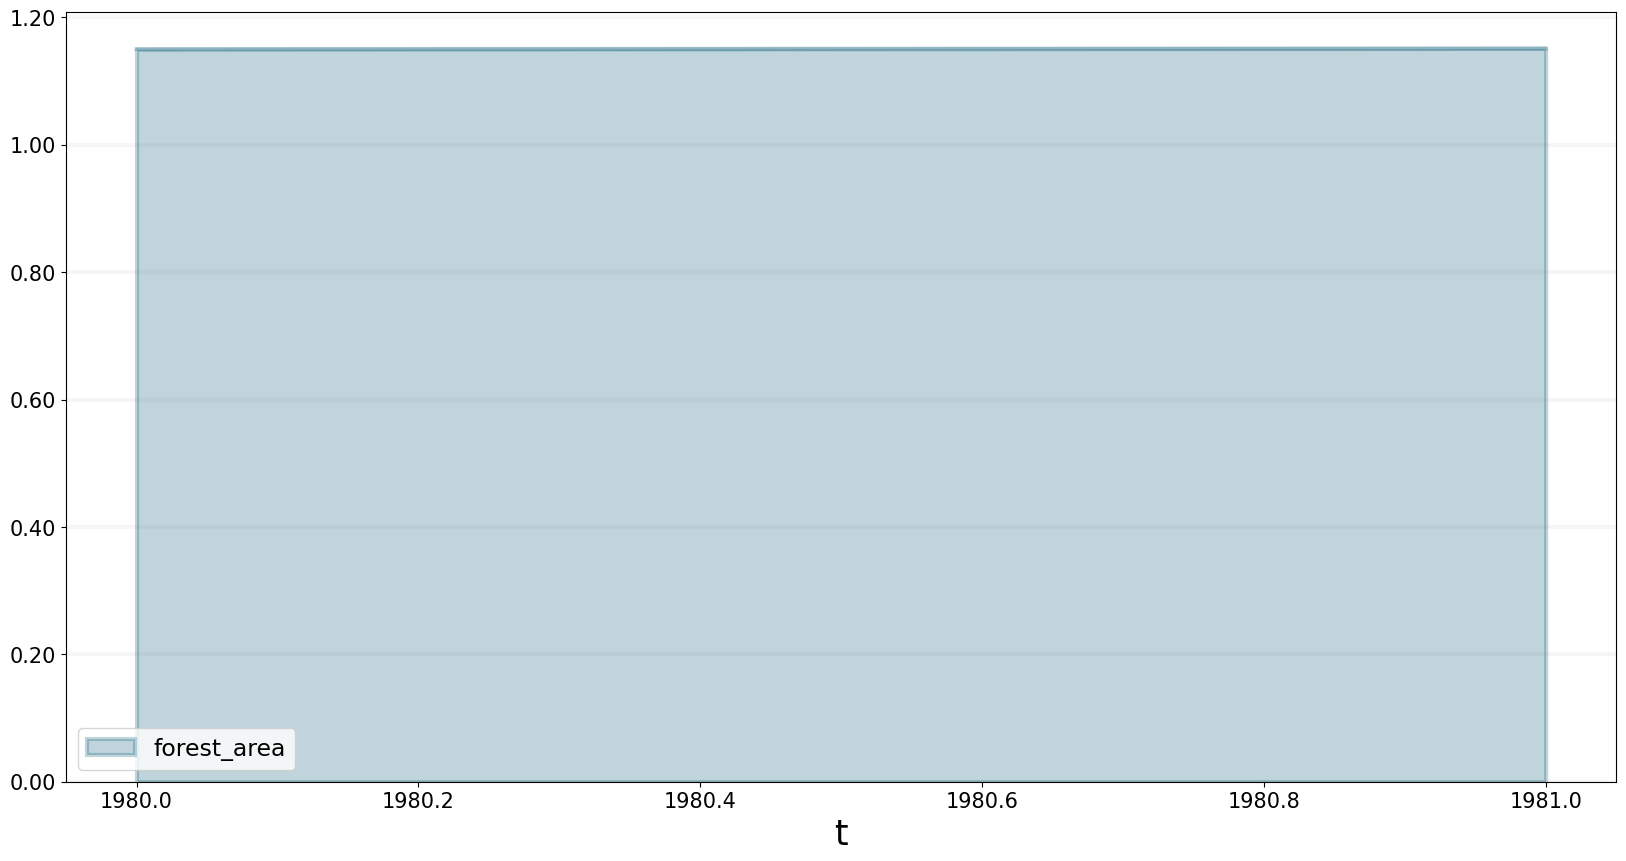

In [8]:
## Beispiel-Flow


# Scenario Manager
scenario_manager = {
    "Forrest2.0": {
        "model": model,
        "base_points": {
            "productivity": [
                [0.0, 0.4],
                [0.25, 0.444],
                [0.5, 0.506],
                [0.75, 0.594],
                [1.0, 1.0],
                [1.25, 1.119],
                [1.5, 1.1625],
                [1.75, 1.2125],
                [2.0, 1.2375],
                [2.25, 1.245],
                [2.5, 1.25]
            ]
        }
    }
}

bptk.register_scenario_manager(scenario_manager)

# Szenario registrieren
bptk.register_scenarios(
    scenarios={
        "Forrest2.0a": {}
    },
    scenario_manager="Forrest2.0"
)

# Waldfläche simulieren und plotten
bptk.plot_scenarios(
    scenarios=["Forrest2.0a"],
    scenario_managers=["Forrest2.0"],
    equations=["forest_area"]
)

In [9]:
import BPTK_Py
import importlib.metadata
import inspect

print("BPTK module:", BPTK_Py.__version__)
print("Package:", importlib.metadata.version("BPTK-Py"))

# Prüfen, welche SD-DSL-Funktionen verfügbar sind
try:
    import BPTK_Py.sddsl.functions as sd

    print("\nVerfügbare Funktionen:")
    for name in [
        "lookup",
        "time",
        "If",
        "random",
        "Random",
        "normal",
        "uniform",
        "montecarlo",
        "pulse"
    ]:
        obj = getattr(sd, name, None)
        print(name, "->", obj)

except Exception as e:
    print("Importproblem:", repr(e))

# Prüfen, welche Methoden dein Model besitzt
print("\nModel-Methoden:")
for name in ["stock", "flow", "converter", "biflow"]:
    print(name, "->", hasattr(Model, name))

BPTK module: 0.38.4
Package: 2.2.2

Verfügbare Funktionen:
lookup -> <function lookup at 0x000002348730ADE0>
time -> <function time at 0x000002348730A660>
If -> <function If at 0x000002348730B420>
random -> <function random at 0x000002348730B2E0>
Random -> <class 'BPTK_Py.sddsl.operators.Random'>
normal -> <function normal at 0x00000234873185E0>
uniform -> <function uniform at 0x000002348730B240>
montecarlo -> <function montecarlo at 0x0000023487318540>
pulse -> <function pulse at 0x000002348730AE80>

Model-Methoden:
stock -> True
flow -> True
converter -> True
biflow -> True


In [13]:
import inspect

print("MODEL-IDENTITÄT")
print("model:", id(model))
print("manager.model:", id(manager.model))
print("scenario.model:", id(scenario.model))

print("\nGLEICHES MODELL?")
print("manager.model is model:", manager.model is model)
print("scenario.model is model:", scenario.model is model)

print("\nSCENARIO-ERGEBNIS")
print("Typ:", type(scenario.result))
print("Spalten:", scenario.result.columns.tolist())
display(scenario.result.head(5))

print("\nEVALUATE_EQUATION")
print(inspect.signature(model.evaluate_equation))




print("MODEL:")
print(type(model))
print("Model-ID:", id(model))

print("\nVerfügbare Methoden:")
print([
    x for x in dir(model)
    if "eval" in x.lower() or "sim" in x.lower()
])

print("\nSCENARIO:")
print(type(scenario))
print(vars(scenario).keys())

print("\nMANAGER:")
print(type(manager))
print(vars(manager).keys())

print("Modell:")
print(list(model.equations.keys()))

print("\nSzenario-Attribute:")
for key, value in vars(scenario).items():
    print(key, type(value))

for name in [
    "_damage_from_events",
    "tree_mortality",
    "deadwood_formation",
    "deadwood_decomposition",
    "deadwood_removal"
]:
    element = model.equations[name]
    print(name, type(element).__name__)


for eq in [
    "tree_mortality",
    "deadwood_formation",
    "deadwood_decomposition",
    "deadwood_removal"
]:
    print("\nTEST:", eq)

    result = bptk.run_scenarios(
        scenarios=["test"],
        scenario_managers=["SwissForest_test"],
        equations=[eq],
        return_format="df"
    )

    if result is None:
        print("Keine Daten zurückgegeben")
    else:
        print(result.columns.tolist())
        display(result.head(3))

print("Alle Modellgleichungen:")
print(list(model.equations.keys()))

MODEL-IDENTITÄT
model: 2416803811152
manager.model: 2416803811152
scenario.model: 2416803388560

GLEICHES MODELL?
manager.model is model: True
scenario.model is model: False

SCENARIO-ERGEBNIS
Typ: <class 'pandas.core.frame.DataFrame'>
Spalten: ['deadwood_removal']


,deadwood_removal
t,
1980.0,0
1981.0,0
1982.0,0
1983.0,0
1984.0,0



EVALUATE_EQUATION
(name, t)
MODEL:
<class 'BPTK_Py.modeling.model.Model'>
Model-ID: 2416803811152

Verfügbare Methoden:
['evaluate_equation']

SCENARIO:
<class 'BPTK_Py.scenariomanager.scenario.SimulationScenario'>
dict_keys(['dictionary', 'scenario_manager', 'model', '_SimulationScenario__sd_simulation', 'stoptime', 'starttime', 'dt', 'constants', 'points', 'name', 'result'])

MANAGER:
<class 'BPTK_Py.scenariomanager.scenario_manager_sd.ScenarioManagerSd'>
dict_keys(['scenarios', 'name', 'type', 'model', 'model_file', 'source', 'base_constants', 'base_points', 'filenames'])
Modell:
['forest_area', 'forest_health', 'wald_verlust', 'deadwood', 'canopy_density', 'agrar', 'freespace', 'climate_data', 'agrar_data', '_ngrowth', '_wiederaufforstung', '_rodung', '_verlust', '_decrease_agrar', '_damage_from_climate', '_damage_from_events', 'deadwood_decomposition', 'deadwood_removal', '_deadwood_reabsorption', 'climate_severity', 'drought_heat', 'acid_deposition', 'event_intensity', 'forest_r

,deadwood_decomposition
t,
1980.0,0



TEST: deadwood_removal
['deadwood_removal']


,deadwood_removal
t,
1980.0,0
1981.0,0
1982.0,0


Alle Modellgleichungen:
['forest_area', 'forest_health', 'wald_verlust', 'deadwood', 'canopy_density', 'agrar', 'freespace', 'climate_data', 'agrar_data', '_ngrowth', '_wiederaufforstung', '_rodung', '_verlust', '_decrease_agrar', '_damage_from_climate', '_damage_from_events', 'deadwood_decomposition', 'deadwood_removal', '_deadwood_reabsorption', 'climate_severity', 'drought_heat', 'acid_deposition', 'event_intensity', 'forest_resilience', 'vulnerability', 'health_recovery', 'health_damage', 'tree_mortality', 'deadwood_formation', 'canopy_regrowth', 'canopy_loss']


In [14]:
print("Gleiches Modell:")
print("manager.model:", manager.model is model)
print("scenario.model:", scenario.model is model)

print("\nScenario-Ergebnis:")
print("Shape:", scenario.result.shape)
print("Spalten:", scenario.result.columns.tolist())
display(scenario.result.head(5))

for t in [1980, 1981, 1982]:
    print(f"\nJahr {t}")

    for name in [
        "forest_area",
        "forest_health",
        "_damage_from_events",
        "tree_mortality",
        "deadwood_formation",
        "deadwood_decomposition",
        "deadwood_removal",
        "deadwood"
    ]:
        try:
            value = model.evaluate_equation(name, t)
            print(f"{name}: {value}")
        except Exception as e:
            print(f"{name}: FEHLER: {type(e).__name__}: {e}")

Gleiches Modell:
manager.model: True
scenario.model: False

Scenario-Ergebnis:
Shape: (47, 1)
Spalten: ['deadwood_removal']


,deadwood_removal
t,
1980.0,0
1981.0,0
1982.0,0
1983.0,0
1984.0,0



Jahr 1980
forest_area: 1.15
forest_health: 1.0
_damage_from_events: 0.0023
tree_mortality: 0.00575
deadwood_formation: 0.01035
deadwood_decomposition: 0
deadwood_removal: 0
deadwood: 0.0

Jahr 1981
forest_area: 1.15122
forest_health: 0.99
_damage_from_events: 0.002417562
tree_mortality: 0.0058545293099999994
deadwood_formation: 0.010689653309999998
deadwood_decomposition: 0.0005175000000000001
deadwood_removal: 0
deadwood: 0.01035

Jahr 1982
forest_area: 1.1524434782231099
forest_health: 0.9806
_damage_from_events: 0.0025353756520908417
tree_mortality: 0.005954491061022293
deadwood_formation: 0.011025242365203976
deadwood_decomposition: 0.0010261076655
deadwood_removal: 0
deadwood: 0.02052215331
